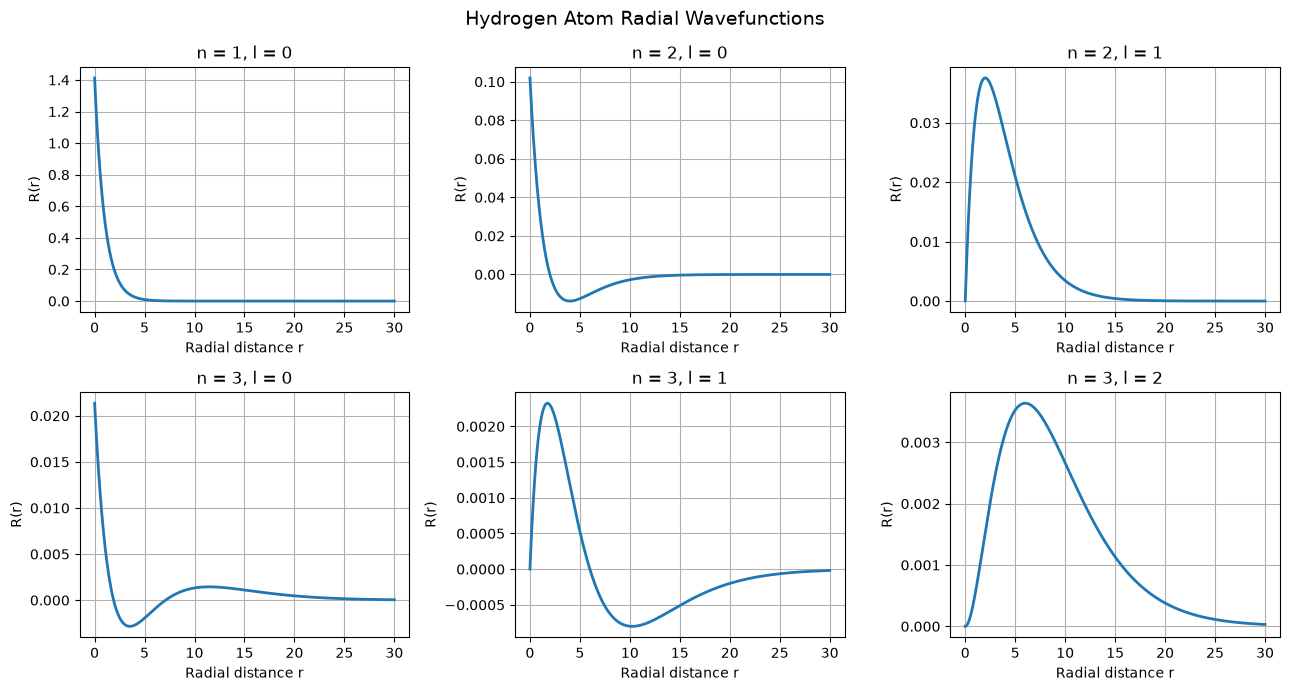

In [2]:

import numpy as np
import matplotlib.pyplot as plt
import math


a = 1.0


r = np.linspace(0.001, 30, 1000)



def coefficients(n, l):

    total = n - l - 1
    c = [1.0]

    for j in range(total):

        numerator = 2 * (j + l + 1 - n)
        denominator = (j + 1) * (j + 2*l + 2)

        next_value = numerator * c[j] / denominator
        c.append(next_value)

    return c



def radial_function(n, l):

    rho = r / (a * n)

    c = coefficients(n, l)

    
    P = np.zeros(len(r))

    for j in range(len(c)):
        P = P + c[j] * rho**j

    
    N1 = (2 / (n*a))**(l + 1.5)

    N2 = math.sqrt(
        math.factorial(n-l-1) /
        (2*n*math.factorial(n+1))
    )

    N = N1 * N2

    
    R = N * (rho**(l+1)) * np.exp(-rho) * P / r

    return R



states = [
    (1,0),
    (2,0),
    (2,1),
    (3,0),
    (3,1),
    (3,2)
]



fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for i in range(len(states)):

    n, l = states[i]

    R = radial_function(n, l)

    row = i // 3
    col = i % 3

    axes[row, col].plot(r, R, linewidth=2)

    axes[row, col].set_title(
        "n = " + str(n) + ", l = " + str(l)
    )

    axes[row, col].set_xlabel("Radial distance r")
    axes[row, col].set_ylabel("R(r)")

    axes[row, col].grid()



plt.suptitle("Hydrogen Atom Radial Wavefunctions", fontsize=14)

plt.tight_layout()
plt.show()
